In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, avg, round, when, desc
)

In [3]:
spark = SparkSession.builder \
    .appName("Customer_Reviews_Analysis") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Session Started Successfully!")

Spark Session Started Successfully!


In [4]:
dataset_path = os.path.join(os.getcwd(), "01_Dataset")

print("Current Folder:", os.getcwd())
print("Dataset Folder Exists:", os.path.exists(dataset_path))
print("Files in Dataset Folder:")
print(os.listdir(dataset_path))

Current Folder: C:\Users\dell\Desktop\CART_TO_DOOR_PROJECT
Dataset Folder Exists: True
Files in Dataset Folder:
['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [5]:
reviews = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .option("multiLine", "true") \
    .option("quote", '"') \
    .option("escape", '"') \
    .csv(os.path.join(dataset_path, "olist_order_reviews_dataset.csv"))

print("Customer Reviews Data Loaded Successfully!")

Customer Reviews Data Loaded Successfully!


In [6]:
print("Total Customer Reviews:", reviews.count())

Total Customer Reviews: 99224


In [7]:
print("Reviews Dataset Schema:")
reviews.printSchema()

print("First 5 Customer Reviews:")
reviews.show(5, truncate=False)

Reviews Dataset Schema:
root
 |-- review_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- review_score: integer (nullable = true)
 |-- review_comment_title: string (nullable = true)
 |-- review_comment_message: string (nullable = true)
 |-- review_creation_date: timestamp (nullable = true)
 |-- review_answer_timestamp: timestamp (nullable = true)

First 5 Customer Reviews:
+--------------------------------+--------------------------------+------------+--------------------+----------------------------------------------------------------------------------------------------+--------------------+-----------------------+
|review_id                       |order_id                        |review_score|review_comment_title|review_comment_message                                                                              |review_creation_date|review_answer_timestamp|
+--------------------------------+--------------------------------+------------+--------------------+--

In [8]:
rating_distribution = reviews.groupBy("review_score") \
    .count() \
    .orderBy("review_score")

rating_distribution.show()

+------------+-----+
|review_score|count|
+------------+-----+
|           1|11424|
|           2| 3151|
|           3| 8179|
|           4|19142|
|           5|57328|
+------------+-----+



In [9]:
average_rating = reviews.select(
    round(avg("review_score"), 2).alias("average_rating")
)

average_rating.show()

+--------------+
|average_rating|
+--------------+
|          4.09|
+--------------+



In [10]:
reviews = reviews.withColumn(
    "sentiment",
    when(col("review_score") <= 2, "Negative")
    .when(col("review_score") == 3, "Neutral")
    .otherwise("Positive")
)

reviews.select("review_score", "sentiment").show(10)

+------------+---------+
|review_score|sentiment|
+------------+---------+
|           4| Positive|
|           5| Positive|
|           5| Positive|
|           5| Positive|
|           5| Positive|
|           1| Negative|
|           5| Positive|
|           5| Positive|
|           5| Positive|
|           4| Positive|
+------------+---------+
only showing top 10 rows



In [11]:
total_reviews = reviews.count()

sentiment_summary = reviews.groupBy("sentiment") \
    .count() \
    .withColumn(
        "percentage",
        round((col("count") / total_reviews) * 100, 2)
    ) \
    .orderBy(desc("count"))

sentiment_summary.show()

+---------+-----+----------+
|sentiment|count|percentage|
+---------+-----+----------+
| Positive|76470|     77.07|
| Negative|14575|     14.69|
|  Neutral| 8179|      8.24|
+---------+-----+----------+



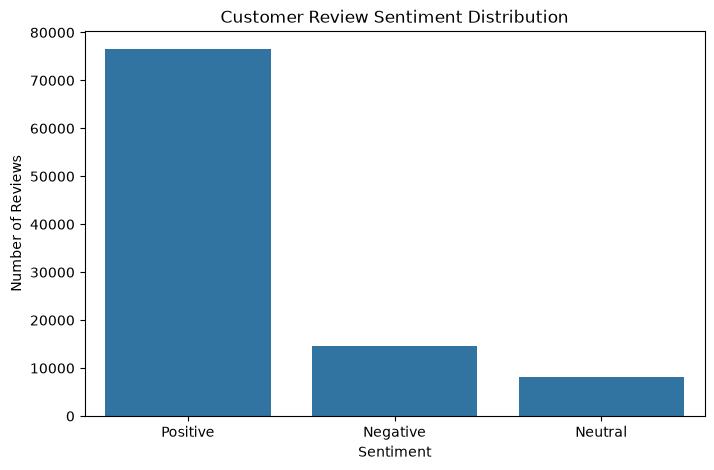

In [12]:
sentiment_pd = sentiment_summary.toPandas()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=sentiment_pd,
    x="sentiment",
    y="count"
)

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [13]:
negative_reviews = reviews.filter(
    col("review_score") <= 2
)

negative_reviews.select(
    "review_score",
    "review_comment_title",
    "review_comment_message"
).show(20, truncate=False)

+------------+-----------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|review_score|review_comment_title   |review_comment_message                                                                                                                                                                                     |
+------------+-----------------------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|1           |NULL                   |NULL                                                                                                                                                                                                       |
|2           |NULL          

In [14]:
negative_with_comments = negative_reviews.filter(
    col("review_comment_message").isNotNull()
)

negative_without_comments = negative_reviews.filter(
    col("review_comment_message").isNull()
)

print("Negative Reviews with Comments:", negative_with_comments.count())
print("Negative Reviews without Comments:", negative_without_comments.count())

Negative Reviews with Comments: 10890
Negative Reviews without Comments: 3685


In [15]:
orders = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .csv(os.path.join(dataset_path, "olist_orders_dataset.csv"))

print("Orders Dataset Loaded Successfully!")
print("Total Orders:", orders.count())

Orders Dataset Loaded Successfully!
Total Orders: 99441


In [16]:
orders.select(
    "order_id",
    "customer_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
).show(5, truncate=False)

+--------------------------------+--------------------------------+------------+------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|delivered   |2017-10-02 10:56:33     |2017-10-10 21:25:13          |2017-10-18 00:00:00          |
|53cdb2fc8bc7dce0b6741e2150273451|b0830fb4747a6c6d20dea0b8c802d7ef|delivered   |2018-07-24 20:41:37     |2018-08-07 15:27:45          |2018-08-13 00:00:00          |
|47770eb9100c2d0c44946d9cf07ec65d|41ce2a54c0b03bf3443c3d931a367089|delivered   |2018-08-08 08:38:49     |2018-08-17 18:06:29          |2018-09-04 00:00:00          |
|949

In [17]:
reviews_orders = reviews.join(
    orders.select(
        "order_id",
        "order_status",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ),
    on="order_id",
    how="inner"
)

print("Reviews and Orders Joined Successfully!")
print("Total Joined Records:", reviews_orders.count())

reviews_orders.select(
    "order_id",
    "review_score",
    "sentiment",
    "order_status",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
).show(5, truncate=False)

Reviews and Orders Joined Successfully!
Total Joined Records: 99224
+--------------------------------+------------+---------+------------+-----------------------------+-----------------------------+
|order_id                        |review_score|sentiment|order_status|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+------------+---------+------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|4           |Positive |delivered   |2017-10-10 21:25:13          |2017-10-18 00:00:00          |
|53cdb2fc8bc7dce0b6741e2150273451|4           |Positive |delivered   |2018-08-07 15:27:45          |2018-08-13 00:00:00          |
|47770eb9100c2d0c44946d9cf07ec65d|5           |Positive |delivered   |2018-08-17 18:06:29          |2018-09-04 00:00:00          |
|949d5b44dbf5de918fe9c16f97b45f8a|5           |Positive |delivered   |2017-12-02 00:28:42          |2017-12-15 00:00:00          |
|ad21c59c0840e6

In [18]:
from pyspark.sql.functions import to_date

reviews_orders = reviews_orders.filter(
    (col("order_status") == "delivered") &
    col("order_delivered_customer_date").isNotNull() &
    col("order_estimated_delivery_date").isNotNull()
)

reviews_orders = reviews_orders.withColumn(
    "delivery_status",
    when(
        to_date("order_delivered_customer_date") <=
        to_date("order_estimated_delivery_date"),
        "On Time"
    ).otherwise("Late")
)

print("Delivered Reviews Records:", reviews_orders.count())

reviews_orders.select(
    "review_score",
    "sentiment",
    "delivery_status"
).show(10)

Delivered Reviews Records: 96353
+------------+---------+---------------+
|review_score|sentiment|delivery_status|
+------------+---------+---------------+
|           4| Positive|        On Time|
|           4| Positive|        On Time|
|           5| Positive|        On Time|
|           5| Positive|        On Time|
|           5| Positive|        On Time|
|           4| Positive|        On Time|
|           5| Positive|        On Time|
|           1| Negative|        On Time|
|           5| Positive|        On Time|
|           1| Negative|        On Time|
+------------+---------+---------------+
only showing top 10 rows



In [19]:
delivery_rating = reviews_orders.groupBy("delivery_status") \
    .agg(
        count("*").alias("total_reviews"),
        round(avg("review_score"), 2).alias("average_rating")
    ) \
    .orderBy("delivery_status")

delivery_rating.show()

+---------------+-------------+--------------+
|delivery_status|total_reviews|average_rating|
+---------------+-------------+--------------+
|           Late|         6409|          2.27|
|        On Time|        89944|          4.29|
+---------------+-------------+--------------+



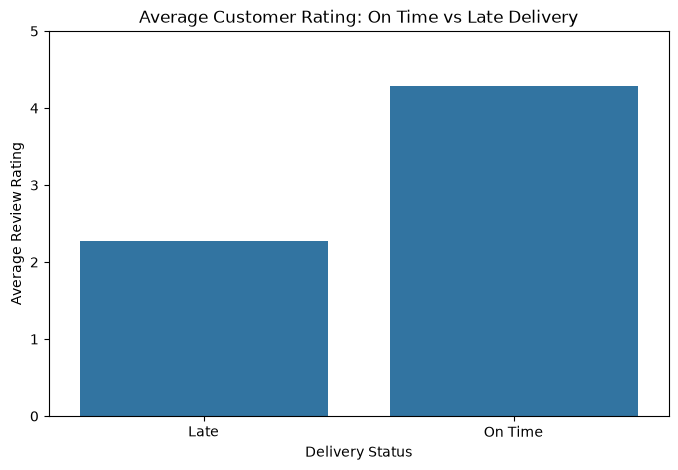

In [20]:
delivery_rating_pd = delivery_rating.toPandas()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=delivery_rating_pd,
    x="delivery_status",
    y="average_rating"
)

plt.title("Average Customer Rating: On Time vs Late Delivery")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Rating")
plt.ylim(0, 5)
plt.show()

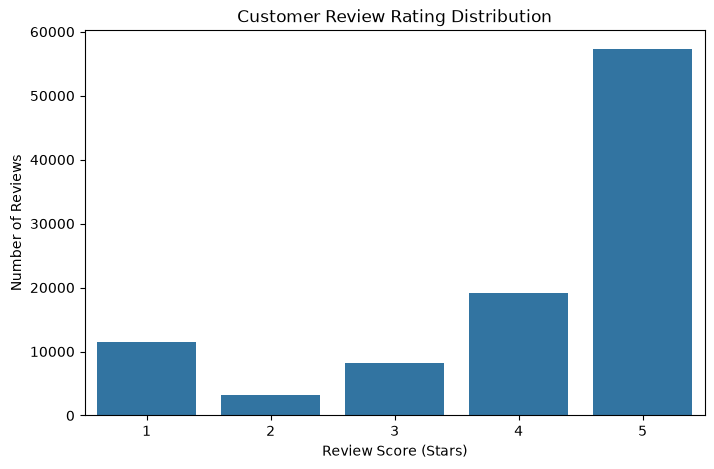

In [21]:
rating_pd = rating_distribution.toPandas()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=rating_pd,
    x="review_score",
    y="count"
)

plt.title("Customer Review Rating Distribution")
plt.xlabel("Review Score (Stars)")
plt.ylabel("Number of Reviews")
plt.show()

In [22]:
review_summary = sentiment_summary.toPandas()

review_summary.to_csv(
    "review_summary.csv",
    index=False
)

print("review_summary.csv exported successfully!")

review_summary.csv exported successfully!


In [23]:
delivery_rating_pd = delivery_rating.toPandas()

delivery_rating_pd.to_csv(
    "delivery_rating_summary.csv",
    index=False
)

print("delivery_rating_summary.csv exported successfully!")

delivery_rating_summary.csv exported successfully!


# Final Conclusion – Customer Reviews Analysis

1. A total of 99,224 customer reviews were analysed.
2. The average customer rating was 4.09 out of 5.
3. Positive reviews accounted for 77.07% of all reviews.
4. Negative reviews accounted for 14.69% of all reviews.
5. Neutral reviews accounted for 8.24% of all reviews.
6. Late delivery orders received an average rating of 2.27.
7. On-time delivery orders received an average rating of 4.29.

## Key Finding

Late delivery is strongly associated with lower customer ratings in this dataset. Improving delivery performance may help improve customer satisfaction.

## Final Output Files

- review_summary.csv
- delivery_rating_summary.csv